Billy York


5/11/2026

# SVD-Based Recommendations

## Analysis

### Choosing the Number of Components

> MovieLens topped out at an R2 value ~0.287 with k=50 components, Netflix Prize at an R2 of ~0.187 with k=5 components, Yahoo! R2 Songs at an R2 of ~0.242 with k=450 components, and BoardGameGeek at an R2 of ~0.176 with 25 components. The two high ends are the most surprising, Yahoo! R2 Songs seems like it could keep scaling in spite of a slight dip between 450 and 500 components as its graph looks logarithmic. Netflix Prize starting with its highest R2 at 5 components and decreasing from there was also surprising. My best guess as to why these two extremes occurred is because of user-item matrix density. Netflix Prize is the most dense and Yahoo! R2 Songs is the most sparse. The higher density of Netflix Prize's matrix means during the SVD, it is likely losing more information than it is gaining in latent features. Similarly, there is much less information for Yahoo! R2 Songs to lose, so the latent features are almost entirely additive.

### R2 Scores by # Components Line Plot
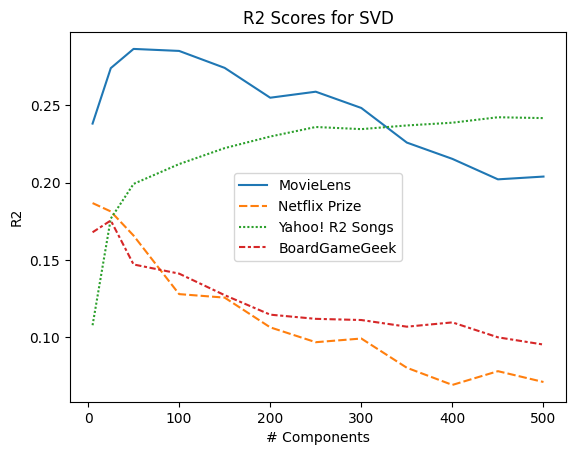

### R2 Scores by # Components Table
| # Components | MovieLens           | Netflix Prize       | Yahoo! R2 Songs     | BoardGameGeek       |
| ------------ | ------------------- | ------------------- | ------------------- | ------------------- |
| 5            | 0.23822961718855912 | 0.18681604217569517 | 0.1078165408336427  | 0.1679359444935241  |
| 25           | 0.274100318711588   | 0.18140021676726673 | 0.17678185641986607 | 0.17555363578958777 |
| 50           | 0.286521131481797   | 0.16579831654393357 | 0.19921768433966064 | 0.14711471632203726 |
| 100          | 0.2852255598257032  | 0.12793932037418243 | 0.21203768858511227 | 0.1411868081636756  |
| 150          | 0.2742598699254963  | 0.1256726731558152  | 0.22236128814570827 | 0.12726065043083484 |
| 200          | 0.25496139071161894 | 0.10644150129209626 | 0.22985281239542993 | 0.114650922577884   |
| 250          | 0.25885253261509744 | 0.0968333322632753  | 0.23602609180928294 | 0.11194179575760384 |
| 300          | 0.24832877836518488 | 0.09921741988396049 | 0.23464405281293915 | 0.11118253067081675 |
| 350          | 0.22594667792441173 | 0.08030312434783649 | 0.2370243692926848  | 0.10687301033972023 |
| 400          | 0.21539863711260068 | 0.0692045752969502  | 0.23880393772567565 | 0.10964825199442088 |
| 450          | 0.2021681358337171  | 0.07809281435447099 | 0.24233038738606286 | 0.09999520139742223 |
| 500          | 0.20396315346879385 | 0.07109205895693632 | 0.24177870307931273 | 0.09529411000680996 |

### How R² Scales with the Number of Components

> Netflix Prize and BoardGameGeek both scaled approximately linearly with a negative slope as k increased. MovieLens seems to be almost parabolic in its scaling with k. Yahoo! R2 Songs looks logarithmic. Around 100 components seems to be the sweet spot among all 4 datasets. It is MovieLens' peak, Yahoo! R2 Songs' point where the slope begins to increase at a decreasing rate, it is right before Netflix Prize's steepest decrease. BoardGameGeek is the only set that suffers from a k=100 as that is its sharpest decrease on the set, but still its third highest R2.

### Compared with kNN and Non-Personalized Recommendations

> BoardGameGeek was the only Dataset to perform worse than the non-personalized recommendations, but it also had the furthest to fall with it having a significantly higher R2 than the rest of the datasets for its non-personalized recommendations. The rest of the datasets significantly improved their R2 from the non-personalized recommendations

### MovieLens Predicted Ratings Distribution
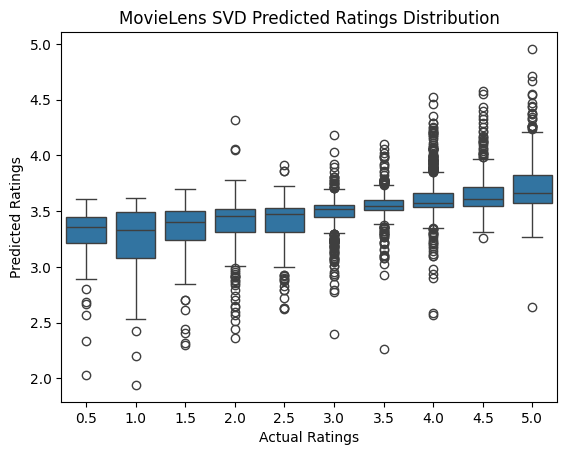

### Netlfix Prize Predicted Ratings Distribution
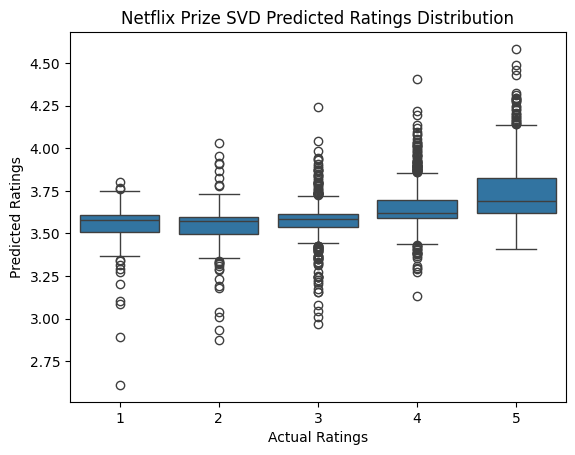

### Yahoo! R2 Songs Predicted Ratings Distribution
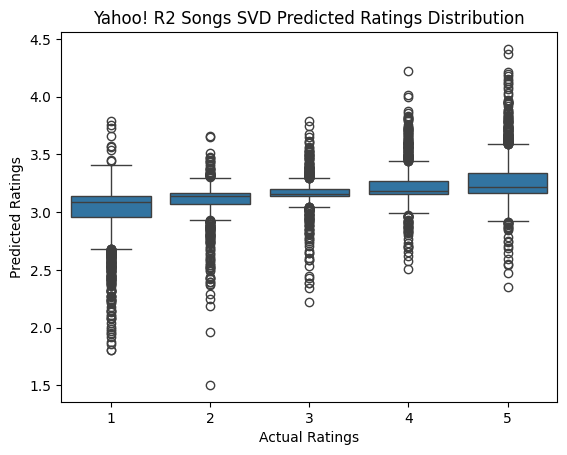

### R2 Scores by Method Table

| Dataset         | Average Rating          | Awareness            | Popularity           | SVD                           |
| --------------- | ----------------------- | -------------------- | -------------------- | ----------------------------- |
| MovieLens       | 0.18443567026140437     | 0.040299782653476765 | 0.05654800407379629  | **k=50 0.286521131481797**    |
| Netflix Prize   | 0.13156114032255972     | 0.009709945199760464 | 0.028105540063984642 | **k=5 0.18681604217569517**   |
| Yahoo! R2 Songs | 0.11168105527134076     | 0.003437395436956116 | 0.007447723620573236 | **k=450 0.24233038738606286** |
| BoardGameGeek   | **0.25942192730239005** | 0.03557139698699113  | 0.06258718932935405  | k=25 0.17555363578958777      |

### Predictions per User

> All four only generated 100 ratings per user, a large difference from the 1000s per user in the original datasets.

### MovieLens Predicted Ratings Per User Distribution
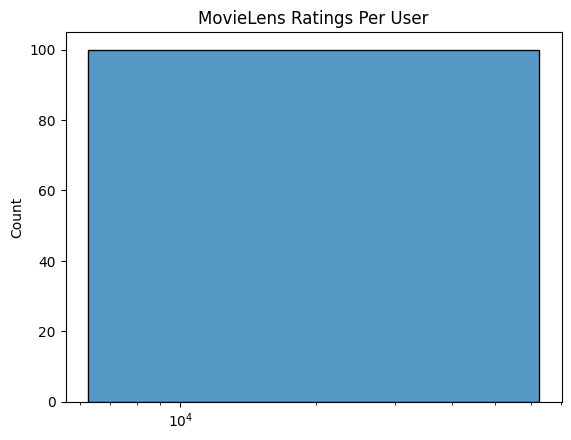

### Netflix Prize Predicted Ratings Per User Distribution
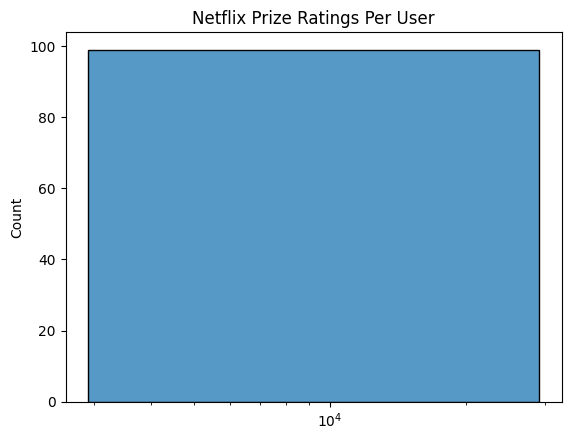

### Yahoo! R2 Songs Predicted Ratings Per User Distribution
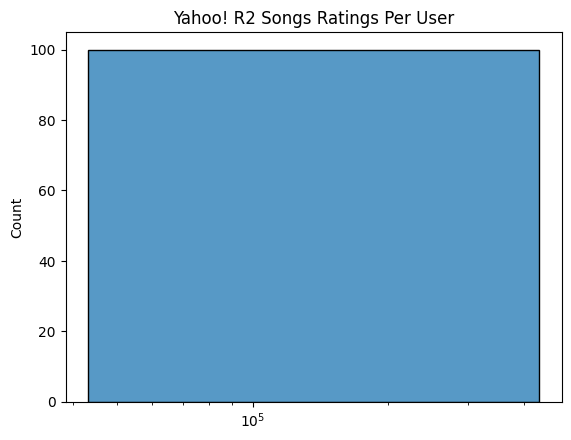

### BoardGameGeek Predicted Ratings Per User Distribution
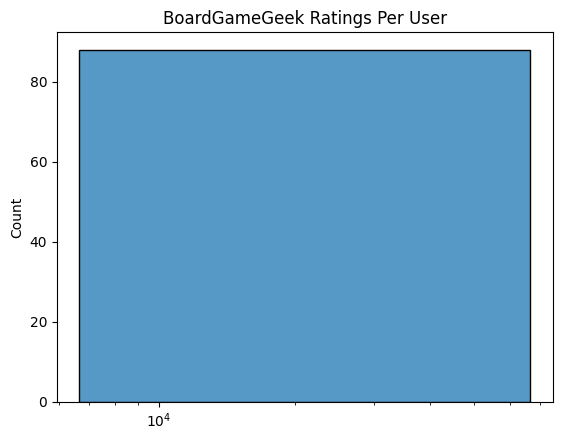

### Strengths and Weaknesses

> SVD (generally) provides more accurate predictions than non-personalized algorithms and with significantly less compute resources required compared to kNN. Its shortcoming is in the number of ratings it can provide. It won't predict a rating for every single item for every single user.

# Implementation

In [1]:
import os
os.environ['POLARS_MAX_THREADS'] = '8'

In [2]:
import numpy as np
import polars as pl

from scipy.sparse import csr_matrix
from scipy.stats import pearsonr

from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import train_test_split

import seaborn as sns
from IPython.display import display, Markdown

In [3]:
BATCH_SIZE = 100

In [4]:
def df_to_sparse(df, n_items):
    uniq_user_ids = set(df['user_id'].unique())
    user_id_to_indices = { orig_user_id : new_user_id for new_user_id, orig_user_id in enumerate(uniq_user_ids) }
    new_user_ids = df['user_id'].replace_strict(user_id_to_indices).to_numpy()
    indices_to_user_ids = { new_user_id : orig_user_id for orig_user_id, new_user_id in user_id_to_indices.items() }

    training_X = csr_matrix(
        (df['rating'].to_numpy(), (new_user_ids, df['item_id'].to_numpy())),
        shape=(len(uniq_user_ids), n_items))

    return training_X, indices_to_user_ids

In [5]:
class SVD:
    def __init__(self, reference_df, query_df):
        self.query_df = query_df
        self.reference_df = reference_df
        
        ref_items = reference_df['item_id'].max() + 1
        query_items = query_df['item_id'].max() + 1
        self.n_items = max(ref_items, query_items)
        
    def fit(self, k):
        self.k = k
        reference_X, self.reference_indices_to_user_ids = df_to_sparse(self.reference_df, self.n_items)
        self.mean_rating = reference_X.sum() / reference_X.nnz
        reference_X.data = reference_X.data - self.mean_rating
        self.svd = TruncatedSVD(n_components=self.k ,random_state=42)
        print('Fitting SVD')
        self.svd.fit(reference_X)
    def predict(self, test_df):
        query_X, self.query_indices_to_user_ids = df_to_sparse(self.query_df, self.n_items)
        query_X.data = query_X.data - self.mean_rating
        print('Getting Embeddings from SVD...')
        embeddings = self.svd.transform(query_X)
        batched_embeddings = np.array_split(embeddings, (embeddings.shape[0] // BATCH_SIZE) + 1)
        predictions = np.array(self.svd.inverse_transform(batched_embeddings[0]))
        print('Batch Processing Embeddings...')
        for i in range(len(batched_embeddings)-1):
            prediction = self.svd.inverse_transform(batched_embeddings[i+1])
            np.append(predictions, prediction)
        print('Converting Processed Embeddings to CSR...')
        pred_csr = csr_matrix(predictions)
        pred_csr.data = pred_csr.data + self.mean_rating
        user_idx_list = []
        print('Converting CSR Index Pointers to Index Array...')
        for i in range(len(pred_csr.indptr)-1):
            user_idx_list.append(np.repeat(i, pred_csr.indptr[i+1] - pred_csr.indptr[i]))
        print('Assembling Index Array...')
        user_idx = np.hstack(user_idx_list)
        pred_df = pl.DataFrame({'user_idx': user_idx, 'item_id': pred_csr.indices, 'pred_rating': pred_csr.data})
        if type(self.query_indices_to_user_ids[0]) is type('a'):
            user_map_df = pl.DataFrame(data=np.array(list(self.query_indices_to_user_ids.items())), schema={'user_idx':pl.Int64, 'user_id':pl.String})
            pred_df = pred_df.join(user_map_df, on='user_idx').select(['user_id', 'item_id', 'pred_rating'])
        else:
            pred_df = pred_df.with_columns(pl.col('user_idx').replace(self.query_indices_to_user_ids).alias('user_id')).select(['user_id', 'item_id', 'pred_rating'])
        pred_df = pred_df.filter(pl.col('user_id').is_in(test_df['user_id'].implode()) & pl.col('item_id').is_in(test_df['item_id'].implode()))
        print('Joining with Test DF...')
        return pred_df

In [6]:
gss = GroupShuffleSplit(n_splits=5, random_state=42)

# Experimental Setup

In [7]:
ml_ratings_df = pl.read_ipc('./movielens_25m.feather', memory_map=False).filter(pl.col('user_id').is_duplicated())
ml_ratings_df.head()

item_id,user_id,rating,__index_level_0__
i64,i64,f64,i64
296,1,5.0,0
306,1,3.5,1
307,1,5.0,2
665,1,5.0,3
899,1,3.5,4


In [8]:
ml_uniq_item_ids = set(ml_ratings_df['item_id'].unique())
ml_item_id_map = { orig_item_id : new_item_id for new_item_id, orig_item_id in enumerate(ml_uniq_item_ids) }

ml_ratings_df = ml_ratings_df.with_columns(item_id = ml_ratings_df['item_id'].replace(ml_item_id_map))

In [9]:
ml_train_idx, ml_test_idx = next(gss.split(ml_ratings_df, None, ml_ratings_df['user_id']))
ml_training_df = ml_ratings_df[ml_train_idx]
ml_leftover_df = ml_ratings_df[ml_test_idx]

ml_query_df, ml_test_df = train_test_split(ml_leftover_df, train_size=0.75, stratify=ml_leftover_df['user_id'], random_state=42)

In [10]:
ml_test_df.head()

item_id,user_id,rating,__index_level_0__
i64,i64,f64,i64
10,9411,3.0,1397990
3252,21096,4.0,3196565
374,61736,3.0,9497776
17852,73461,5.0,11323356
7486,74905,3.0,11552248


In [11]:
ml_svd = SVD(ml_training_df, ml_query_df)

In [12]:
ml_svd.fit(5)
ml_pred_df = ml_svd.predict(ml_test_df)
ml_common_ratings_df = ml_pred_df.join(ml_test_df, on=['user_id', 'item_id'])
ml_result_5 = pearsonr(ml_common_ratings_df['pred_rating'].to_numpy(), ml_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(ml_result_5)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.23822961718855912


In [13]:
ml_svd.fit(25)
ml_pred_df = ml_svd.predict(ml_test_df)
ml_common_ratings_df = ml_pred_df.join(ml_test_df, on=['user_id', 'item_id'])
ml_result_25 = pearsonr(ml_common_ratings_df['pred_rating'].to_numpy(), ml_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(ml_result_25)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.274100318711588


In [14]:
ml_svd.fit(50)
ml_pred_df = ml_svd.predict(ml_test_df)
ml_common_ratings_df = ml_pred_df.join(ml_test_df, on=['user_id', 'item_id'])
ml_result_50 = pearsonr(ml_common_ratings_df['pred_rating'].to_numpy(), ml_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(ml_result_50)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.286521131481797


[Text(0.5, 1.0, 'MovieLens SVD Predicted Ratings Distribution'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

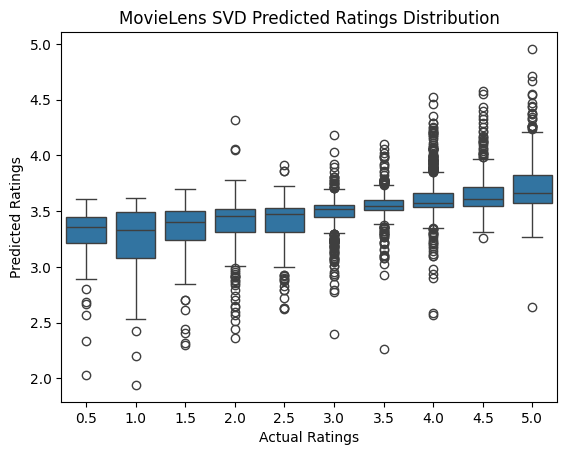

In [15]:
sns.boxplot(x=ml_common_ratings_df['rating'], y=ml_common_ratings_df['pred_rating']).set(title='MovieLens SVD Predicted Ratings Distribution', xlabel='Actual Ratings', ylabel='Predicted Ratings')

[Text(0.5, 1.0, 'MovieLens Ratings Per User')]

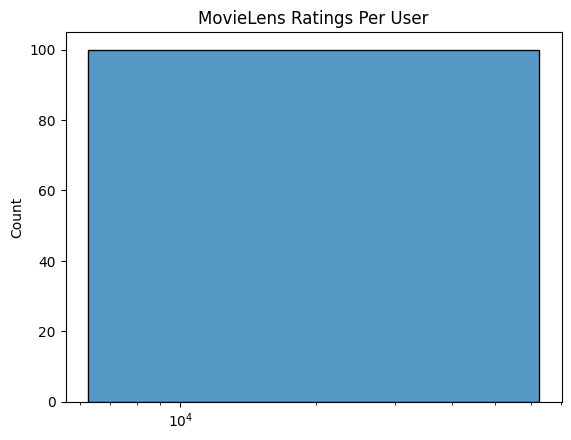

In [16]:
ml_ratings_per_user = ml_pred_df.group_by('user_id').agg(num_ratings=pl.col('item_id').n_unique())
sns.histplot(data=ml_ratings_per_user['num_ratings'], log_scale=(True, False)).set(title='MovieLens Ratings Per User')

In [17]:
ml_svd.fit(100)
ml_pred_df = ml_svd.predict(ml_test_df)
ml_common_ratings_df = ml_pred_df.join(ml_test_df, on=['user_id', 'item_id'])
ml_result_100 = pearsonr(ml_common_ratings_df['pred_rating'].to_numpy(), ml_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(ml_result_100)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.2852255598257032


In [18]:
ml_svd.fit(150)
ml_pred_df = ml_svd.predict(ml_test_df)
ml_common_ratings_df = ml_pred_df.join(ml_test_df, on=['user_id', 'item_id'])
ml_result_150 = pearsonr(ml_common_ratings_df['pred_rating'].to_numpy(), ml_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(ml_result_150)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.2742598699254963


In [19]:
ml_svd.fit(200)
ml_pred_df = ml_svd.predict(ml_test_df)
ml_common_ratings_df = ml_pred_df.join(ml_test_df, on=['user_id', 'item_id'])
ml_result_200 = pearsonr(ml_common_ratings_df['pred_rating'].to_numpy(), ml_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(ml_result_200)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.25496139071161894


In [20]:
ml_svd.fit(250)
ml_pred_df = ml_svd.predict(ml_test_df)
ml_common_ratings_df = ml_pred_df.join(ml_test_df, on=['user_id', 'item_id'])
ml_result_250 = pearsonr(ml_common_ratings_df['pred_rating'].to_numpy(), ml_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(ml_result_250)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.25885253261509744


In [21]:
ml_svd.fit(300)
ml_pred_df = ml_svd.predict(ml_test_df)
ml_common_ratings_df = ml_pred_df.join(ml_test_df, on=['user_id', 'item_id'])
ml_result_300 = pearsonr(ml_common_ratings_df['pred_rating'].to_numpy(), ml_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(ml_result_300)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.24832877836518488


In [22]:
ml_svd.fit(350)
ml_pred_df = ml_svd.predict(ml_test_df)
ml_common_ratings_df = ml_pred_df.join(ml_test_df, on=['user_id', 'item_id'])
ml_result_350 = pearsonr(ml_common_ratings_df['pred_rating'].to_numpy(), ml_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(ml_result_350)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.22594667792441173


In [23]:
ml_svd.fit(400)
ml_pred_df = ml_svd.predict(ml_test_df)
ml_common_ratings_df = ml_pred_df.join(ml_test_df, on=['user_id', 'item_id'])
ml_result_400 = pearsonr(ml_common_ratings_df['pred_rating'].to_numpy(), ml_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(ml_result_400)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.21539863711260068


In [24]:
ml_svd.fit(450)
ml_pred_df = ml_svd.predict(ml_test_df)
ml_common_ratings_df = ml_pred_df.join(ml_test_df, on=['user_id', 'item_id'])
ml_result_450 = pearsonr(ml_common_ratings_df['pred_rating'].to_numpy(), ml_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(ml_result_450)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.2021681358337171


In [25]:
ml_svd.fit(500)
ml_pred_df = ml_svd.predict(ml_test_df)
ml_common_ratings_df = ml_pred_df.join(ml_test_df, on=['user_id', 'item_id'])
ml_result_500 = pearsonr(ml_common_ratings_df['pred_rating'].to_numpy(), ml_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(ml_result_500)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.20396315346879385


In [26]:
del ml_svd
del ml_pred_df
del ml_common_ratings_df

ml_results = {
    5: ml_result_5,
    25: ml_result_25,
    50: ml_result_50,
    100: ml_result_100,
    150: ml_result_150,
    200: ml_result_200,
    250: ml_result_250,
    300: ml_result_300,
    350: ml_result_350,
    400: ml_result_400,
    450: ml_result_450,
    500: ml_result_500
}

In [27]:
np_ratings_df = pl.read_ipc('./netflix_prize.feather', memory_map=False).filter(pl.col('user_id').is_duplicated())
np_ratings_df.head()

item_id,user_id,rating
i64,i64,i64
1,1488844,3
1,822109,5
1,885013,4
1,30878,4
1,823519,3


In [28]:
np_uniq_item_ids = set(np_ratings_df['item_id'].unique())
np_item_id_map = { orig_item_id : new_item_id for new_item_id, orig_item_id in enumerate(np_uniq_item_ids) }

np_ratings_df = np_ratings_df.with_columns(item_id = np_ratings_df['item_id'].replace(np_item_id_map))

In [29]:
np_train_idx, np_test_idx = next(gss.split(np_ratings_df, None, np_ratings_df['user_id']))
np_training_df = np_ratings_df[np_train_idx]
np_leftover_df = np_ratings_df[np_test_idx]

np_query_df, np_test_df = train_test_split(np_leftover_df, train_size=0.75, stratify=np_leftover_df['user_id'], random_state=42)

In [30]:
np_test_df.head()

item_id,user_id,rating
i64,i64,i64
3965,1652819,4
7330,2430991,3
4830,1228566,3
5400,2397142,4
5153,162854,4


In [31]:
np_svd = SVD(np_training_df, np_query_df)

In [32]:
np_svd.fit(5)
np_pred_df = np_svd.predict(np_test_df)
np_common_ratings_df = np_pred_df.join(np_test_df, on=['user_id', 'item_id'])
np_result_5 = pearsonr(np_common_ratings_df['pred_rating'].to_numpy(), np_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(np_result_5)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.18681604217569517


[Text(0.5, 1.0, 'Netflix Prize SVD Predicted Ratings Distribution'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

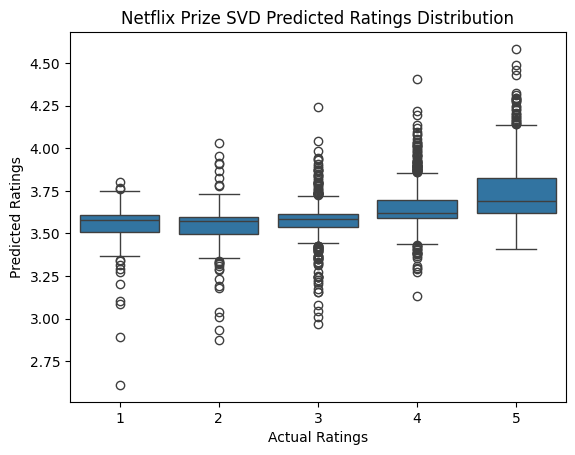

In [33]:
sns.boxplot(x=np_common_ratings_df['rating'], y=np_common_ratings_df['pred_rating']).set(title='Netflix Prize SVD Predicted Ratings Distribution', xlabel='Actual Ratings', ylabel='Predicted Ratings')

[Text(0.5, 1.0, 'Netflix Prize Ratings Per User')]

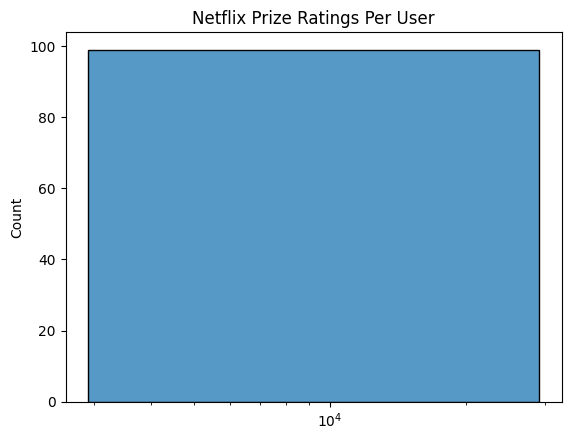

In [34]:
np_ratings_per_user = np_pred_df.group_by('user_id').agg(num_ratings=pl.col('item_id').n_unique())
sns.histplot(data=np_ratings_per_user['num_ratings'], log_scale=(True, False)).set(title='Netflix Prize Ratings Per User')

In [35]:
np_svd.fit(25)
np_pred_df = np_svd.predict(np_test_df)
np_common_ratings_df = np_pred_df.join(np_test_df, on=['user_id', 'item_id'])
np_result_25 = pearsonr(np_common_ratings_df['pred_rating'].to_numpy(), np_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(np_result_25)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.18140021676726673


In [36]:
np_svd.fit(50)
np_pred_df = np_svd.predict(np_test_df)
np_common_ratings_df = np_pred_df.join(np_test_df, on=['user_id', 'item_id'])
np_result_50 = pearsonr(np_common_ratings_df['pred_rating'].to_numpy(), np_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(np_result_50)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.16579831654393357


In [37]:
np_svd.fit(100)
np_pred_df = np_svd.predict(np_test_df)
np_common_ratings_df = np_pred_df.join(np_test_df, on=['user_id', 'item_id'])
np_result_100 = pearsonr(np_common_ratings_df['pred_rating'].to_numpy(), np_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(np_result_100)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.12793932037418243


In [38]:
np_svd.fit(150)
np_pred_df = np_svd.predict(np_test_df)
np_common_ratings_df = np_pred_df.join(np_test_df, on=['user_id', 'item_id'])
np_result_150 = pearsonr(np_common_ratings_df['pred_rating'].to_numpy(), np_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(np_result_150)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.1256726731558152


In [39]:
np_svd.fit(200)
np_pred_df = np_svd.predict(np_test_df)
np_common_ratings_df = np_pred_df.join(np_test_df, on=['user_id', 'item_id'])
np_result_200 = pearsonr(np_common_ratings_df['pred_rating'].to_numpy(), np_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(np_result_200)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.10644150129209626


In [40]:
np_svd.fit(250)
np_pred_df = np_svd.predict(np_test_df)
np_common_ratings_df = np_pred_df.join(np_test_df, on=['user_id', 'item_id'])
np_result_250 = pearsonr(np_common_ratings_df['pred_rating'].to_numpy(), np_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(np_result_250)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.0968333322632753


In [41]:
np_svd.fit(300)
np_pred_df = np_svd.predict(np_test_df)
np_common_ratings_df = np_pred_df.join(np_test_df, on=['user_id', 'item_id'])
np_result_300 = pearsonr(np_common_ratings_df['pred_rating'].to_numpy(), np_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(np_result_300)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.09921741988396049


In [42]:
np_svd.fit(350)
np_pred_df = np_svd.predict(np_test_df)
np_common_ratings_df = np_pred_df.join(np_test_df, on=['user_id', 'item_id'])
np_result_350 = pearsonr(np_common_ratings_df['pred_rating'].to_numpy(), np_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(np_result_350)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.08030312434783649


In [43]:
np_svd.fit(400)
np_pred_df = np_svd.predict(np_test_df)
np_common_ratings_df = np_pred_df.join(np_test_df, on=['user_id', 'item_id'])
np_result_400 = pearsonr(np_common_ratings_df['pred_rating'].to_numpy(), np_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(np_result_400)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.0692045752969502


In [44]:
np_svd.fit(450)
np_pred_df = np_svd.predict(np_test_df)
np_common_ratings_df = np_pred_df.join(np_test_df, on=['user_id', 'item_id'])
np_result_450 = pearsonr(np_common_ratings_df['pred_rating'].to_numpy(), np_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(np_result_450)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.07809281435447099


In [45]:
np_svd.fit(500)
np_pred_df = np_svd.predict(np_test_df)
np_common_ratings_df = np_pred_df.join(np_test_df, on=['user_id', 'item_id'])
np_result_500 = pearsonr(np_common_ratings_df['pred_rating'].to_numpy(), np_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(np_result_500)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.07109205895693632


In [46]:
del np_svd
del np_pred_df
del np_common_ratings_df

np_results = {
    5: np_result_5,
    25: np_result_25,
    50: np_result_50,
    100: np_result_100,
    150: np_result_150,
    200: np_result_200,
    250: np_result_250,
    300: np_result_300,
    350: np_result_350,
    400: np_result_400,
    450: np_result_450,
    500: np_result_500
}

In [47]:
yh_ratings_df = pl.read_ipc('./yahoo_r2_songs.subsample.feather', memory_map=False).filter(pl.col('user_id').is_duplicated())
yh_ratings_df.head()

item_id,user_id,rating
i64,i64,i64
166,0,5
2245,0,4
3637,0,4
5580,0,4
5859,0,4


In [48]:
yh_uniq_item_ids = set(yh_ratings_df['item_id'].unique())
yh_item_id_map = { orig_item_id : new_item_id for new_item_id, orig_item_id in enumerate(yh_uniq_item_ids) }

yh_ratings_df = yh_ratings_df.with_columns(item_id = yh_ratings_df['item_id'].replace(yh_item_id_map))

In [49]:
yh_train_idx, yh_test_idx = next(gss.split(yh_ratings_df, None, yh_ratings_df['user_id']))
yh_training_df = yh_ratings_df[yh_train_idx]
yh_leftover_df = yh_ratings_df[yh_test_idx]

yh_query_df, yh_test_df = train_test_split(yh_leftover_df, train_size=0.75, stratify=yh_leftover_df['user_id'], random_state=42)

In [50]:
yh_test_df.head()

item_id,user_id,rating
i64,i64,i64
55152,126798,1
5019,148180,5
76973,23114,5
61824,146302,5
128979,135071,1


In [51]:
yh_svd = SVD(yh_training_df, yh_query_df)

In [52]:
yh_svd.fit(5)
yh_pred_df = yh_svd.predict(yh_test_df)
yh_common_ratings_df = yh_pred_df.join(yh_test_df, on=['user_id', 'item_id'])
yh_result_5 = pearsonr(yh_common_ratings_df['pred_rating'].to_numpy(), yh_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(yh_result_5)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.1078165408336427


In [53]:
yh_svd.fit(25)
yh_pred_df = yh_svd.predict(yh_test_df)
yh_common_ratings_df = yh_pred_df.join(yh_test_df, on=['user_id', 'item_id'])
yh_result_25 = pearsonr(yh_common_ratings_df['pred_rating'].to_numpy(), yh_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(yh_result_25)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.17678185641986607


In [54]:
yh_svd.fit(50)
yh_pred_df = yh_svd.predict(yh_test_df)
yh_common_ratings_df = yh_pred_df.join(yh_test_df, on=['user_id', 'item_id'])
yh_result_50 = pearsonr(yh_common_ratings_df['pred_rating'].to_numpy(), yh_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(yh_result_50)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.19921768433966064


In [55]:
yh_svd.fit(100)
yh_pred_df = yh_svd.predict(yh_test_df)
yh_common_ratings_df = yh_pred_df.join(yh_test_df, on=['user_id', 'item_id'])
yh_result_100 = pearsonr(yh_common_ratings_df['pred_rating'].to_numpy(), yh_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(yh_result_100)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.21203768858511227


In [56]:
yh_svd.fit(150)
yh_pred_df = yh_svd.predict(yh_test_df)
yh_common_ratings_df = yh_pred_df.join(yh_test_df, on=['user_id', 'item_id'])
yh_result_150 = pearsonr(yh_common_ratings_df['pred_rating'].to_numpy(), yh_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(yh_result_150)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.22236128814570827


In [57]:
yh_svd.fit(200)
yh_pred_df = yh_svd.predict(yh_test_df)
yh_common_ratings_df = yh_pred_df.join(yh_test_df, on=['user_id', 'item_id'])
yh_result_200 = pearsonr(yh_common_ratings_df['pred_rating'].to_numpy(), yh_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(yh_result_200)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.22985281239542993


In [58]:
yh_svd.fit(250)
yh_pred_df = yh_svd.predict(yh_test_df)
yh_common_ratings_df = yh_pred_df.join(yh_test_df, on=['user_id', 'item_id'])
yh_result_250 = pearsonr(yh_common_ratings_df['pred_rating'].to_numpy(), yh_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(yh_result_250)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.23602609180928294


In [59]:
yh_svd.fit(300)
yh_pred_df = yh_svd.predict(yh_test_df)
yh_common_ratings_df = yh_pred_df.join(yh_test_df, on=['user_id', 'item_id'])
yh_result_300 = pearsonr(yh_common_ratings_df['pred_rating'].to_numpy(), yh_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(yh_result_300)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.23464405281293915


In [60]:
yh_svd.fit(350)
yh_pred_df = yh_svd.predict(yh_test_df)
yh_common_ratings_df = yh_pred_df.join(yh_test_df, on=['user_id', 'item_id'])
yh_result_350 = pearsonr(yh_common_ratings_df['pred_rating'].to_numpy(), yh_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(yh_result_350)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.2370243692926848


In [61]:
yh_svd.fit(400)
yh_pred_df = yh_svd.predict(yh_test_df)
yh_common_ratings_df = yh_pred_df.join(yh_test_df, on=['user_id', 'item_id'])
yh_result_400 = pearsonr(yh_common_ratings_df['pred_rating'].to_numpy(), yh_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(yh_result_400)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.23880393772567565


In [62]:
yh_svd.fit(450)
yh_pred_df = yh_svd.predict(yh_test_df)
yh_common_ratings_df = yh_pred_df.join(yh_test_df, on=['user_id', 'item_id'])
yh_result_450 = pearsonr(yh_common_ratings_df['pred_rating'].to_numpy(), yh_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(yh_result_450)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.24233038738606286


[Text(0.5, 1.0, 'Yahoo! R2 Songs SVD Predicted Ratings Distribution'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

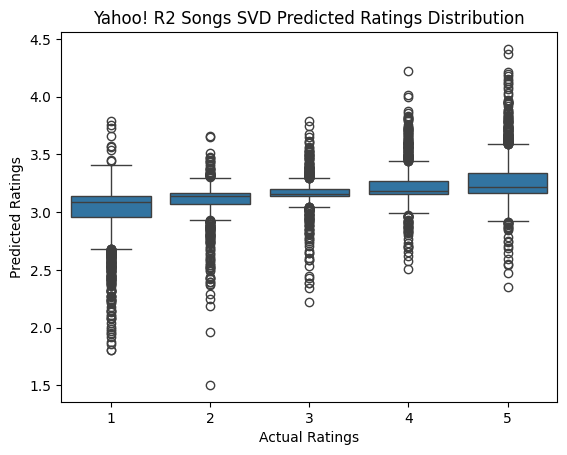

In [63]:
sns.boxplot(x=yh_common_ratings_df['rating'], y=yh_common_ratings_df['pred_rating']).set(title='Yahoo! R2 Songs SVD Predicted Ratings Distribution', xlabel='Actual Ratings', ylabel='Predicted Ratings')

[Text(0.5, 1.0, 'Yahoo! R2 Songs Ratings Per User')]

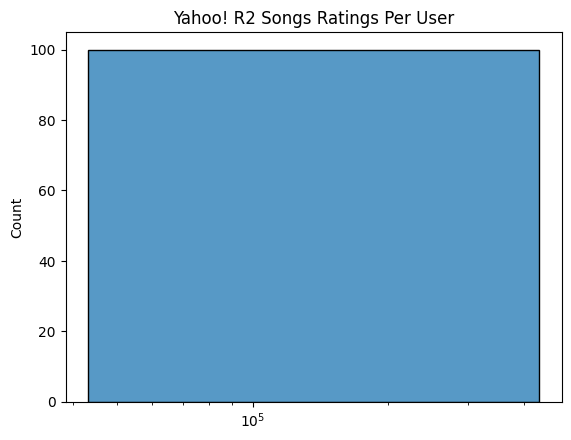

In [64]:
yh_ratings_per_user = yh_pred_df.group_by('user_id').agg(num_ratings=pl.col('item_id').n_unique())
sns.histplot(data=yh_ratings_per_user['num_ratings'], log_scale=(True, False)).set(title='Yahoo! R2 Songs Ratings Per User')

In [65]:
yh_svd.fit(500)
yh_pred_df = yh_svd.predict(yh_test_df)
yh_common_ratings_df = yh_pred_df.join(yh_test_df, on=['user_id', 'item_id'])
yh_result_500 = pearsonr(yh_common_ratings_df['pred_rating'].to_numpy(), yh_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(yh_result_500)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.24177870307931273


In [66]:
del yh_svd
del yh_pred_df
del yh_common_ratings_df

yh_results = {
    5: yh_result_5,
    25: yh_result_25,
    50: yh_result_50,
    100: yh_result_100,
    150: yh_result_150,
    200: yh_result_200,
    250: yh_result_250,
    300: yh_result_300,
    350: yh_result_350,
    400: yh_result_400,
    450: yh_result_450,
    500: yh_result_500
}

In [67]:
bg_ratings_df = pl.read_ipc('./boardgamegeek.feather', memory_map=False).fill_null('').filter(pl.col('user_id').is_duplicated())
bg_ratings_df.head()

item_id,user_id,rating
i64,str,f64
213788,"""Tonydorrf""",8.0
213788,"""tachyon14k""",8.0
213788,"""Ungotter""",8.0
213788,"""brainlocki3""",8.0
213788,"""PPMP""",8.0


In [68]:
bg_uniq_item_ids = set(bg_ratings_df['item_id'].unique())
bg_item_id_map = { orig_item_id : new_item_id for new_item_id, orig_item_id in enumerate(bg_uniq_item_ids) }

bg_ratings_df = bg_ratings_df.with_columns(item_id = bg_ratings_df['item_id'].replace(bg_item_id_map))

In [69]:
bg_train_idx, bg_test_idx = next(gss.split(bg_ratings_df, None, bg_ratings_df['user_id']))
bg_training_df = bg_ratings_df[bg_train_idx]
bg_leftover_df = bg_ratings_df[bg_test_idx]

bg_query_df, bg_test_df = train_test_split(bg_leftover_df, train_size=0.75, stratify=bg_leftover_df['user_id'], random_state=42)

In [70]:
bg_test_df.head()

item_id,user_id,rating
i64,str,f64
18492,"""BigRedGamer""",9.0
10280,"""Paris Bovell""",9.0
16840,"""Banton""",7.0
13398,"""amrollahi""",8.0
411,"""heuer""",7.0


In [71]:
bg_svd = SVD(bg_training_df, bg_query_df)

In [72]:
bg_svd.fit(5)
bg_pred_df = bg_svd.predict(bg_test_df)
bg_common_ratings_df = bg_pred_df.join(bg_test_df, on=['user_id', 'item_id'])
bg_result_5 = pearsonr(bg_common_ratings_df['pred_rating'].to_numpy(), bg_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(bg_result_5)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.09959698270712442


In [73]:
bg_svd.fit(25)
bg_pred_df = bg_svd.predict(bg_test_df)
bg_common_ratings_df = bg_pred_df.join(bg_test_df, on=['user_id', 'item_id'])
bg_result_25 = pearsonr(bg_common_ratings_df['pred_rating'].to_numpy(), bg_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(bg_result_25)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.1192704336384223


[Text(0.5, 1.0, 'BoardGameGeek Ratings Per User')]

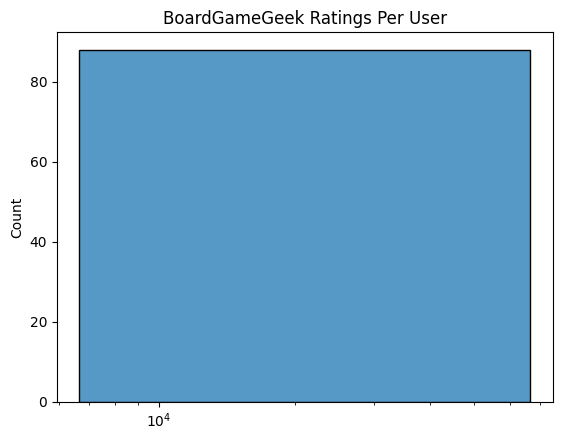

In [74]:
bg_ratings_per_user = bg_pred_df.group_by('user_id').agg(num_ratings=pl.col('item_id').n_unique())
sns.histplot(data=bg_ratings_per_user['num_ratings'], log_scale=(True, False)).set(title='BoardGameGeek Ratings Per User')

In [75]:
bg_svd.fit(50)
bg_pred_df = bg_svd.predict(bg_test_df)
bg_common_ratings_df = bg_pred_df.join(bg_test_df, on=['user_id', 'item_id'])
bg_result_50 = pearsonr(bg_common_ratings_df['pred_rating'].to_numpy(), bg_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(bg_result_50)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.12084680008583246


In [76]:
bg_svd.fit(100)
bg_pred_df = bg_svd.predict(bg_test_df)
bg_common_ratings_df = bg_pred_df.join(bg_test_df, on=['user_id', 'item_id'])
bg_result_100 = pearsonr(bg_common_ratings_df['pred_rating'].to_numpy(), bg_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(bg_result_100)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.08927300405501766


In [77]:
bg_svd.fit(150)
bg_pred_df = bg_svd.predict(bg_test_df)
bg_common_ratings_df = bg_pred_df.join(bg_test_df, on=['user_id', 'item_id'])
bg_result_150 = pearsonr(bg_common_ratings_df['pred_rating'].to_numpy(), bg_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(bg_result_150)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.08859929077303179


In [78]:
bg_svd.fit(200)
bg_pred_df = bg_svd.predict(bg_test_df)
bg_common_ratings_df = bg_pred_df.join(bg_test_df, on=['user_id', 'item_id'])
bg_result_200 = pearsonr(bg_common_ratings_df['pred_rating'].to_numpy(), bg_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(bg_result_200)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.0710204888672106


In [79]:
bg_svd.fit(250)
bg_pred_df = bg_svd.predict(bg_test_df)
bg_common_ratings_df = bg_pred_df.join(bg_test_df, on=['user_id', 'item_id'])
bg_result_250 = pearsonr(bg_common_ratings_df['pred_rating'].to_numpy(), bg_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(bg_result_250)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.0805163349174907


In [80]:
bg_svd.fit(300)
bg_pred_df = bg_svd.predict(bg_test_df)
bg_common_ratings_df = bg_pred_df.join(bg_test_df, on=['user_id', 'item_id'])
bg_result_300 = pearsonr(bg_common_ratings_df['pred_rating'].to_numpy(), bg_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(bg_result_300)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.08356024549021702


In [81]:
bg_svd.fit(350)
bg_pred_df = bg_svd.predict(bg_test_df)
bg_common_ratings_df = bg_pred_df.join(bg_test_df, on=['user_id', 'item_id'])
bg_result_350 = pearsonr(bg_common_ratings_df['pred_rating'].to_numpy(), bg_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(bg_result_350)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.07685364256417768


In [82]:
bg_svd.fit(400)
bg_pred_df = bg_svd.predict(bg_test_df)
bg_common_ratings_df = bg_pred_df.join(bg_test_df, on=['user_id', 'item_id'])
bg_result_400 = pearsonr(bg_common_ratings_df['pred_rating'].to_numpy(), bg_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(bg_result_400)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.06984298532831347


In [83]:
bg_svd.fit(450)
bg_pred_df = bg_svd.predict(bg_test_df)
bg_common_ratings_df = bg_pred_df.join(bg_test_df, on=['user_id', 'item_id'])
bg_result_450 = pearsonr(bg_common_ratings_df['pred_rating'].to_numpy(), bg_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(bg_result_450)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.05458555847977485


In [84]:
bg_svd.fit(500)
bg_pred_df = bg_svd.predict(bg_test_df)
bg_common_ratings_df = bg_pred_df.join(bg_test_df, on=['user_id', 'item_id'])
bg_result_500 = pearsonr(bg_common_ratings_df['pred_rating'].to_numpy(), bg_common_ratings_df['rating'].to_numpy()).statistic ** 2

print(bg_result_500)

Fitting SVD
Getting Embeddings from SVD...
Batch Processing Embeddings...
Converting Processed Embeddings to CSR...
Converting CSR Index Pointers to Index Array...
Assembling Index Array...
Joining with Test DF...
0.06010889491944041


In [85]:
del bg_svd
del bg_pred_df
del bg_common_ratings_df

bg_results = {
    5: bg_result_5,
    25: bg_result_25,
    50: bg_result_50,
    100: bg_result_100,
    150: bg_result_150,
    200: bg_result_200,
    250: bg_result_250,
    300: bg_result_300,
    350: bg_result_350,
    400: bg_result_400,
    450: bg_result_450,
    500: bg_result_500
}

In [86]:
display(Markdown(f'| # Components | MovieLens | Netflix Prize | Yahoo! R2 Songs | BoardGameGeek |\n| - | - | - | - | - |\n| 5 | {ml_results[5]} | {np_results[5]} | {yh_results[5]} | {bg_results[5]} |\n| 25 | {ml_results[25]} | {np_results[25]} | {yh_results[25]} | {bg_results[25]} |\n| 50 | {ml_results[50]} | {np_results[50]} | {yh_results[50]} | {bg_results[50]} |\n| 100 | {ml_results[100]} | {np_results[100]} | {yh_results[100]} | {bg_results[100]} |\n| 150 | {ml_results[150]} | {np_results[150]} | {yh_results[150]} | {bg_results[150]} |\n| 200 | {ml_results[200]} | {np_results[200]} | {yh_results[200]} | {bg_results[200]} |\n| 250 | {ml_results[250]} | {np_results[250]} | {yh_results[250]} | {bg_results[250]} |\n| 300 | {ml_results[300]} | {np_results[300]} | {yh_results[300]} | {bg_results[300]} |\n| 350 | {ml_results[350]} | {np_results[350]} | {yh_results[350]} | {bg_results[350]} |\n| 400 | {ml_results[400]} | {np_results[400]} | {yh_results[400]} | {bg_results[400]} |\n| 450 | {ml_results[450]} | {np_results[450]} | {yh_results[450]} | {bg_results[450]} |\n| 500 | {ml_results[500]} | {np_results[500]} | {yh_results[500]} | {bg_results[500]} |'))

| # Components | MovieLens | Netflix Prize | Yahoo! R2 Songs | BoardGameGeek |
| - | - | - | - | - |
| 5 | 0.23822961718855912 | 0.18681604217569517 | 0.1078165408336427 | 0.09959698270712442 |
| 25 | 0.274100318711588 | 0.18140021676726673 | 0.17678185641986607 | 0.1192704336384223 |
| 50 | 0.286521131481797 | 0.16579831654393357 | 0.19921768433966064 | 0.12084680008583246 |
| 100 | 0.2852255598257032 | 0.12793932037418243 | 0.21203768858511227 | 0.08927300405501766 |
| 150 | 0.2742598699254963 | 0.1256726731558152 | 0.22236128814570827 | 0.08859929077303179 |
| 200 | 0.25496139071161894 | 0.10644150129209626 | 0.22985281239542993 | 0.0710204888672106 |
| 250 | 0.25885253261509744 | 0.0968333322632753 | 0.23602609180928294 | 0.0805163349174907 |
| 300 | 0.24832877836518488 | 0.09921741988396049 | 0.23464405281293915 | 0.08356024549021702 |
| 350 | 0.22594667792441173 | 0.08030312434783649 | 0.2370243692926848 | 0.07685364256417768 |
| 400 | 0.21539863711260068 | 0.0692045752969502 | 0.23880393772567565 | 0.06984298532831347 |
| 450 | 0.2021681358337171 | 0.07809281435447099 | 0.24233038738606286 | 0.05458555847977485 |
| 500 | 0.20396315346879385 | 0.07109205895693632 | 0.24177870307931273 | 0.06010889491944041 |

[Text(0.5, 1.0, 'R2 Scores for SVD'),
 Text(0.5, 0, '# Components'),
 Text(0, 0.5, 'R2')]

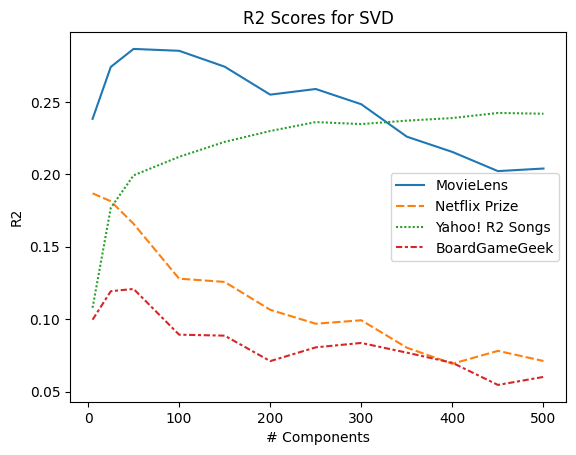

In [87]:
sns.lineplot({'MovieLens':ml_results, 'Netflix Prize':np_results, 'Yahoo! R2 Songs':yh_results, 'BoardGameGeek':bg_results}).set(title='R2 Scores for SVD', xlabel='# Components', ylabel='R2')